# Bankruptcy prediction

**Question:** Can we use fewer financial variables and still build a useful decision tree?

- **Prediction target:** `Bankrupt?` (1 = bankruptcy, 0 = no bankruptcy), predicted from 95 financial ratios.
- **Decision to support:** an analyst has limited time and must choose which companies get a closer manual review. The model ranks companies by bankruptcy risk and flags the riskiest ones.
- **Evaluation metric:** average precision (AP), together with recall and precision (defined in section 2).
- **Approach:** combined, variable selection with L1 regularization followed by a decision tree.

Our steps:
1. Load and check the data.
2. Explore the training data and correlations.
3. Select variables with L1 regularization.
4. Compare decision trees and evaluate the final model.

Source: [UCI Taiwanese Bankruptcy Prediction](https://archive.ics.uci.edu/dataset/572/taiwanese+bankruptcy+prediction).
The source describes data collected in Taiwan between 1999 and 2009.

## 1. Imports
Run the cells in order. Keep `data.csv` in the same folder as this notebook. The packages are listed in `requirements.txt`.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import VarianceThreshold, SelectFromModel
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    average_precision_score, precision_score, recall_score,
    accuracy_score, ConfusionMatrixDisplay, PrecisionRecallDisplay
)

In [2]:
random_state = 42
plt.rcParams["figure.figsize"] = (8, 4)

## 2. Load and check the data

In [3]:
data = pd.read_csv("data.csv")
data.columns = data.columns.str.strip()
data.head()

,Bankrupt?,ROA(C) before interest and depreciation before interest,ROA(A) before interest and % after tax,ROA(B) before interest and depreciation after tax,Operating Gross Margin,Realized Sales Gross Margin,Operating Profit Rate,Pre-tax net Interest Rate,After-tax net Interest Rate,Non-industry income and expenditure/revenue,...,Net Income to Total Assets,Total assets to GNP price,No-credit Interval,Gross Profit to Sales,Net Income to Stockholder's Equity,Liability to Equity,Degree of Financial Leverage (DFL),Interest Coverage Ratio (Interest expense to EBIT),Net Income Flag,Equity to Liability
0,1,0.370594,0.424389,0.405750,0.601457,0.601457,0.998969,0.796887,0.808809,0.302646,...,0.716845,0.009219,0.622879,0.601453,0.827890,0.290202,0.026601,0.564050,1,0.016469
1,1,0.464291,0.538214,0.516730,0.610235,0.610235,0.998946,0.797380,0.809301,0.303556,...,0.795297,0.008323,0.623652,0.610237,0.839969,0.283846,0.264577,0.570175,1,0.020794
2,1,0.426071,0.499019,0.472295,0.601450,0.601364,0.998857,0.796403,0.808388,0.302035,...,0.774670,0.040003,0.623841,0.601449,0.836774,0.290189,0.026555,0.563706,1,0.016474
3,1,0.399844,0.451265,0.457733,0.583541,0.583541,0.998700,0.796967,0.808966,0.303350,...,0.739555,0.003252,0.622929,0.583538,0.834697,0.281721,0.026697,0.564663,1,0.023982
4,1,0.465022,0.538432,0.522298,0.598783,0.598783,0.998973,0.797366,0.809304,0.303475,...,0.795016,0.003878,0.623521,0.598782,0.839973,0.278514,0.024752,0.575617,1,0.035490


In [4]:
print("Rows:", data.shape[0])
print("Predictors:", data.shape[1] - 1)

Rows: 6819
Predictors: 95


In [5]:
checks = pd.Series({
    "Missing values": data.isna().sum().sum(),
    "Infinite values": np.isinf(data.to_numpy()).sum(),
    "Duplicate rows": data.duplicated().sum()
})
checks

Missing values     0
Infinite values    0
Duplicate rows     0
dtype: int64

In [6]:
target_counts = data["Bankrupt?"].value_counts().sort_index()
pd.DataFrame({
    "Count": target_counts,
    "Percentage": 100 * target_counts / len(data)
})

,Count,Percentage
Bankrupt?,,
0,6599,96.77372
1,220,3.22628


**Dataset.** 6,819 Taiwanese companies and 95 numeric financial ratios. There are no missing values, infinite values or duplicates. Only 3.23% of the companies are bankrupt (220 cases).

**Preprocessing.** `Net Income Flag` is constant, so we remove it. The ratios have very different scales, so we standardize them before L1 selection. Both steps are fitted on training data only.

**Class imbalance.** Always predicting 0 is right 96.8% of the time but detects no bankruptcy, so accuracy is misleading. We handle the imbalance in three ways:
1. Stratified splits and folds keep about 3.2% of bankruptcies in every part.
2. `class_weight="balanced"` makes a bankrupt company count more during training (see section 7).
3. We judge models with average precision, recall and precision, not accuracy.

**Evaluation metrics.** TP = bankruptcies flagged, FP = false alarms, FN = missed bankruptcies.

- Precision = TP / (TP + FP): share of alerts that are correct.
- Recall = TP / (TP + FN): share of bankruptcies we detect.
- Average precision: AP = $\sum (R_k − R_{k-1}) P_k$, where $P_k$ and $R_k$ are precision and recall when we flag the k highest-risk companies. It summarizes the precision-recall curve over all thresholds and only uses the ranking of the scores.

A random ranking gives AP ≈ 0.032 (the share of bankruptcies). A perfect ranking gives AP = 1.
Missing a bankruptcy is costly, but every alert costs analyst time, so we need both recall and precision. AP is our main score because it does not require choosing a threshold.
Precision and recall in the final table use the default threshold (predicted probability ≥ 0.5).

## 3. Keep a separate test set
We use 80% for training and 20% for testing. `stratify` keeps similar class proportions. From this point, exploration uses the training set. We use the test set only at the end.

In [7]:
X = data.drop(columns="Bankrupt?")
y = data["Bankrupt?"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=random_state
)

## 4. Correlation
We plot the ten predictors most correlated with bankruptcy in the training set.
Pearson correlation measures linear relationships. It does not prove causation and can miss nonlinear patterns.

In [8]:
correlations = X_train.corrwith(y_train).dropna()
top_names = correlations.abs().sort_values(ascending=False).head(10).index

/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:3036: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:3037: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


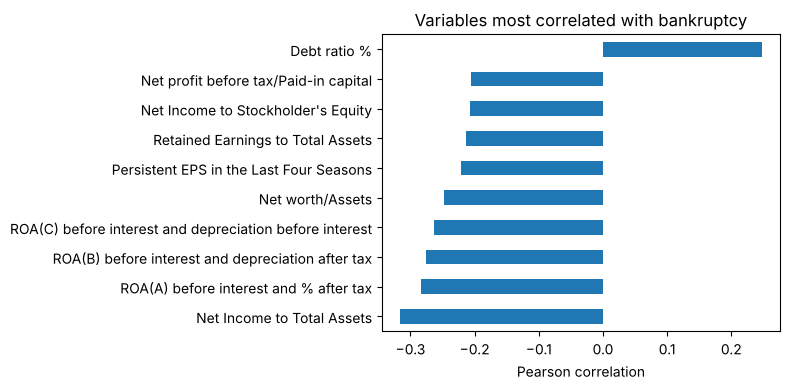

In [9]:
correlations.loc[top_names].sort_values().plot.barh()
plt.xlabel("Pearson correlation")
plt.title("Variables most correlated with bankruptcy")
plt.tight_layout()
plt.show()

## 5. Validation and model settings

We use 5-fold stratified cross-validation on the training set.
Each pipeline learns its preprocessing and selection only from the training part of each fold.

We try a small number of settings:
- Tree depth: 3, 5, 7 or 10.
- Minimum observations per leaf: 10, 30, 50 or 100.
- `class_weight="balanced"` gives more weight to the rare bankruptcy class.

We choose settings using average precision. The test set is not used for tuning.

**Why this grid.** A first, smaller grid (depth 3 or 5, leaf 10 or 30, `C` 0.01 to 1) picked the largest depth, the largest leaf size and the smallest `C`. When the winner sits on the edge of the grid, a value outside the grid might be better. We therefore widened the grid until the best values lie inside it.

In [10]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=random_state)

tree_grid = {
    "tree__max_depth": [3, 5, 7, 10],
    "tree__min_samples_leaf": [10, 30, 50, 100]
}

## 6. Decision tree without variable selection
This model is our reference for measuring the value of selection. It only removes constant columns.

In [11]:
tree_pipeline = Pipeline([
    ("constant", VarianceThreshold()),
    ("tree", DecisionTreeClassifier(
        class_weight="balanced", random_state=random_state
    ))
])

In [12]:
tree_search = GridSearchCV(
    tree_pipeline, tree_grid, scoring="average_precision", cv=cv
)
tree_search.fit(X_train, y_train)

print("Best settings:", tree_search.best_params_)
print("Validation AP:", round(tree_search.best_score_, 3))

Best settings: {'tree__max_depth': 7, 'tree__min_samples_leaf': 50}
Validation AP: 0.295


## 7. LASSO-style selection

**LASSO in the course** (continuous target):
$$\hat\beta = \arg\min_b \; \frac{1}{2n}\|Y - Xb\|_2^2 + \lambda \|b\|_1$$
The L1 penalty sets some coefficients exactly to zero. With orthogonal columns, the solution is soft thresholding: $\hat\beta_j = \text{sign}(W_j)\,(|W_j| - \lambda)_+$, so a variable is dropped when $|W_j| \le \lambda$.

**Our case.** The target is binary, so we replace the squared error by the logistic loss $\ell$. scikit-learn minimizes
$$\min_{w,\,b} \; \|w\|_1 + C \sum_{i=1}^{n} \omega_{y_i}\, \ell\big(y_i,\; b + x_i^\top w\big)$$
- A smaller `C` means a larger $\lambda$ (roughly $\lambda = 1/(nC)$), so more coefficients are zero. We try 0.002, 0.005, 0.01, 0.1 and 1.
- $\omega_{y_i}$ is the class weight. With `class_weight="balanced"`, $\omega_c = n / (2 n_c)$, where $n_c$ is the number of training companies in class $c$.
- Variables with $w_j = 0$ are removed. We keep the others and train a decision tree on them.

`StandardScaler` puts variables on comparable scales, which the L1 penalty needs. Scaling and selection are fitted inside each training fold.

**Limit.** The guarantees of Lecture 4 are for Gaussian regression with a theoretical $\lambda$. Here the loss is logistic and `C` is chosen by cross-validation, so we use the LASSO idea but not its theorems.

In [13]:
n = len(y_train)
class_weights = n / (2 * y_train.value_counts().sort_index())
class_weights.rename("Class weight").round(1)

Bankrupt?
0     0.5
1    15.5
Name: Class weight, dtype: float64

In [14]:
l1_model = LogisticRegression(
    l1_ratio=1,
    solver="liblinear",
    class_weight="balanced",
    max_iter=2000,
    random_state=random_state
)

selected_pipeline = Pipeline([
    ("constant", VarianceThreshold()),
    ("scale", StandardScaler()),
    ("selection", SelectFromModel(l1_model, threshold=0.00001)),
    ("tree", DecisionTreeClassifier(
        class_weight="balanced", random_state=random_state
    ))
])

In [15]:
selection_grid = {
    "selection__estimator__C": [0.002, 0.005, 0.01, 0.1, 1],
    "tree__max_depth": [3, 5, 7, 10],
    "tree__min_samples_leaf": [10, 30, 50, 100]
}

selection_search = GridSearchCV(
    selected_pipeline, selection_grid, scoring="average_precision", cv=cv
)
selection_search.fit(X_train, y_train)

print("Best settings:", selection_search.best_params_)
print("Validation AP:", round(selection_search.best_score_, 3))

Best settings: {'selection__estimator__C': 0.005, 'tree__max_depth': 10, 'tree__min_samples_leaf': 50}
Validation AP: 0.312


## 8. Selected variables
After choosing settings, `GridSearchCV` fits the best pipeline on the full training set. The following variables come from that fitted pipeline.

In [16]:
selected_model = selection_search.best_estimator_
variable_names = X_train.columns[
    selected_model.named_steps["constant"].get_support()
]
selector = selected_model.named_steps["selection"]
selected_names = variable_names[selector.get_support()]

print("Original variables:", X_train.shape[1])
print("Selected variables:", len(selected_names))

Original variables: 95
Selected variables: 10


In [17]:
pd.Series(selected_names, name="Selected variables")

0    ROA(C) before interest and depreciation before...
1              Persistent EPS in the Last Four Seasons
2                           Total debt/Total net worth
3                                         Debt ratio %
4                                     Net worth/Assets
5                                 Total Asset Turnover
6                      Fixed Assets Turnover Frequency
7                      Working Capital to Total Assets
8                               Fixed Assets to Assets
9                           Net Income to Total Assets
Name: Selected variables, dtype: str

## 9. Choose the model before looking at the test results
We recommend the model with the higher mean validation AP. We still report both trees to show whether selection helped.

In [18]:
pd.Series({
    "Tree without selection": tree_search.best_score_,
    "L1 selection + tree": selection_search.best_score_
}, name="Validation AP (5-fold CV)").round(3)

Tree without selection    0.295
L1 selection + tree       0.312
Name: Validation AP (5-fold CV), dtype: float64

In [19]:
if selection_search.best_score_ >= tree_search.best_score_:
    final_name = "L1 selection + tree"
    final_model = selection_search.best_estimator_
else:
    final_name = "Tree without selection"
    final_model = tree_search.best_estimator_

print("Model chosen using validation:", final_name)

Model chosen using validation: L1 selection + tree


## 10. Final test results
The baseline always predicts the most common class.
AP uses probability scores. Precision, recall and accuracy use the default class predictions.
The dashed line is a random ranking (AP ≈ 0.032).

In [20]:
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)

models = {
    "Majority baseline": baseline,
    "Tree without selection": tree_search.best_estimator_,
    "L1 selection + tree": selection_search.best_estimator_
}

In [21]:
results = []

for name, model in models.items():
    prediction = model.predict(X_test)
    probability = model.predict_proba(X_test)[:, 1]
    results.append({
        "Model": name,
        "Average precision": average_precision_score(y_test, probability),
        "Recall": recall_score(y_test, prediction, zero_division=0),
        "Precision": precision_score(y_test, prediction, zero_division=0),
        "Accuracy": accuracy_score(y_test, prediction)
    })

test_results = pd.DataFrame(results).set_index("Model")
test_results.round(3)

,Average precision,Recall,Precision,Accuracy
Model,,,,
Majority baseline,0.032,0.000,0.000,0.968
Tree without selection,0.331,0.864,0.176,0.865
L1 selection + tree,0.298,0.818,0.167,0.862


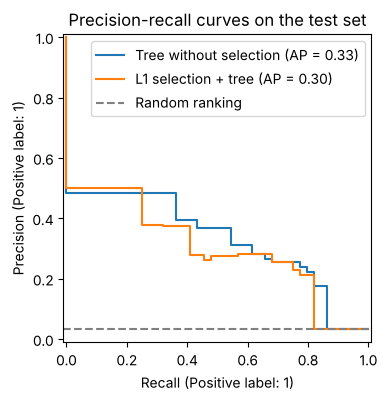

In [22]:
fig, ax = plt.subplots()
for name in ["Tree without selection", "L1 selection + tree"]:
    probability = models[name].predict_proba(X_test)[:, 1]
    PrecisionRecallDisplay.from_predictions(y_test, probability, name=name, ax=ax)
ax.axhline(y_test.mean(), linestyle="--", color="gray", label="Random ranking")
ax.legend()
plt.title("Precision-recall curves on the test set")
plt.show()

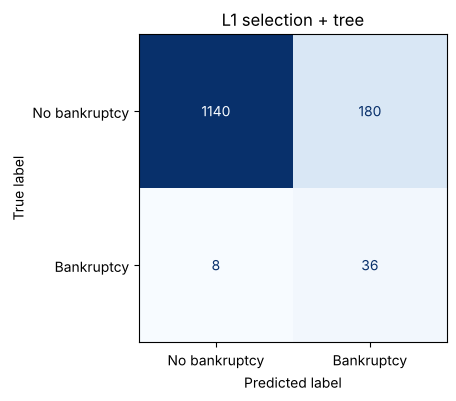

In [23]:
final_prediction = final_model.predict(X_test)

ConfusionMatrixDisplay.from_predictions(
    y_test, final_prediction,
    display_labels=["No bankruptcy", "Bankruptcy"],
    cmap="Blues", colorbar=False
)
plt.title(final_name)
plt.show()

## 11. Understand the combined model
We show the first three levels of the tree after L1 selection. Some branches may continue below the displayed levels. Thresholds use standardized values because this tree follows the scaler.

Because we use balanced class weights, the `value` proportions in the tree are weighted class proportions, not the original class frequencies.

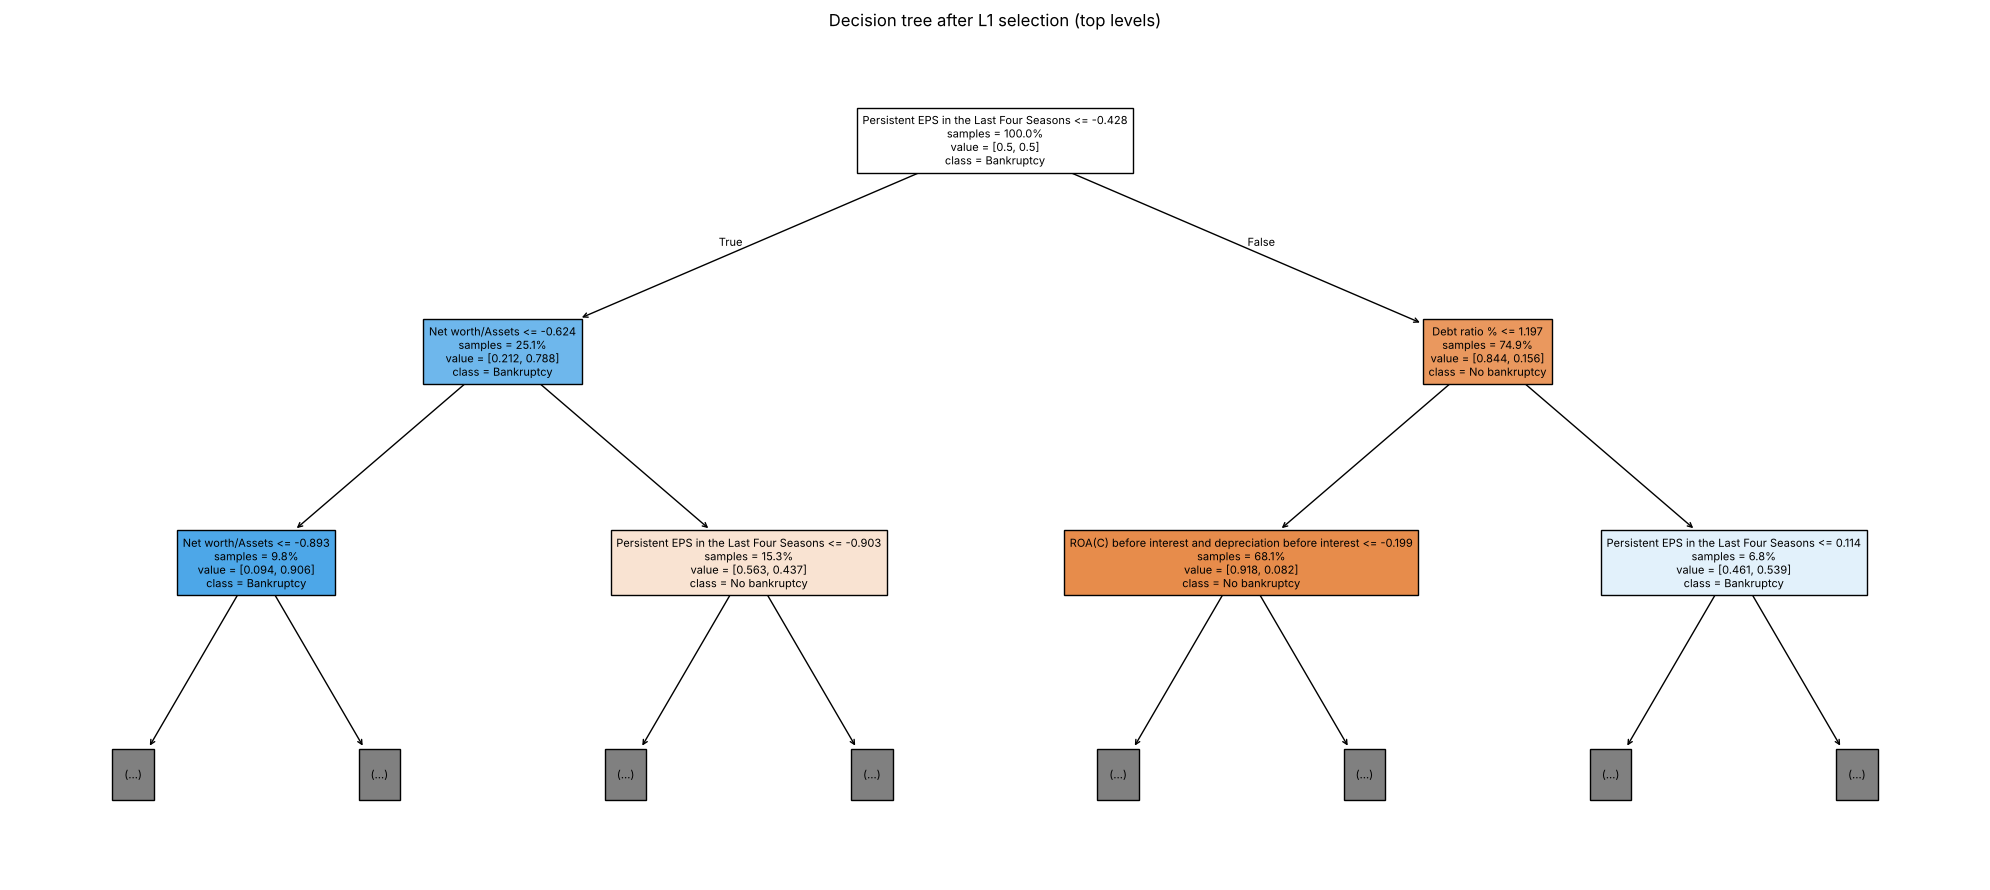

In [24]:
plt.figure(figsize=(20, 9))
plot_tree(
    selected_model.named_steps["tree"],
    feature_names=selected_names.tolist(),
    class_names=["No bankruptcy", "Bankruptcy"],
    max_depth=2,
    filled=True,
    impurity=False,
    proportion=True,
    fontsize=8
)
plt.title("Decision tree after L1 selection (top levels)")
plt.tight_layout()
plt.show()

## 12. Conclusion

L1 kept **10 of 95 variables**. Validation AP increased from **0.295 to 0.312**, so we chose the combined model.

**Tuning.** The best settings lie inside the grid. `C = 0.005` beat both 0.002 and 0.01, and a leaf size of 50 beat both 30 and 100.
Depth 7 and depth 10 gave almost the same score, because leaves of at least 50 companies stop the tree before it reaches that depth.

On the test set, however, the tree without selection was better on every metric: AP **0.331** against **0.298**.
The combined model detected **36 of 44 bankrupt companies** and produced **180 false alarms**.
Its recall was **81.8%** and its precision was **16.7%**.
The tree without selection detected 38 of 44 with 178 false alarms.

**Selection simplified the model strongly (10 instead of 94 variables) while keeping similar predictive performance, but it did not improve it.**
The validation advantage (0.017) and the test disadvantage (0.033) are both smaller than the variation between folds (standard deviation about 0.05), so neither model is reliably better.
The combined model is easier to explain and to monitor, which is why we still recommend it for a first screening.

The model could help prioritize manual reviews, but most alerts are false alarms.
Results depend on one split and only 220 bankruptcy cases.
These historical Taiwanese data may not represent current companies.
Without dates or company IDs, we cannot test performance on future years or separate repeated companies.

The brief also requires a PDF report and an appendix with all relevant LLM prompts and answers verbatim.